# Qualitative Samples — SIM Dataset


In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import h5py

# --- Colormap for segmentation classes ---
class_info = [
    (2,  "#bb2a34"),  # fascia
    (3,  "#e58368"),  # gastrocnemius
    (4,  "#f6b899"),  # soleus
    (5,  "#c0dceb"),  # membrane
    (7,  "#68abd0"),  # VLS
    (8,  "#053061"),  # fat
    (9,  "#cfe6e6"),  # gel
    (11, "#bb2a34"),  # epidermis
    (12, "#67001f"),  # dermis
    (13, "#FFFFFF"),  # vessel (sat)
    (14, "#ffffff"),  # vessel (muscle)
]
class_ids = [item[0] for item in class_info]
colors    = [item[1] for item in class_info]
cmap = ListedColormap(colors)
norm = BoundaryNorm(class_ids + [max(class_ids) + 1], len(colors))


def load_hdf5(filepath, datasets):
    with h5py.File(filepath, "r") as f:
        return [f[ds][()] for ds in datasets]


# --- Publication style ---
plt.rcParams.update({
    "font.family": "arial",
    "font.size": 9,
    "axes.titlesize": 12,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
})


In [ ]:
basepath  = "oa_us_pipeline_data/2025-08-01_14-04-16/data"
sample_id = "000-019-002-012.hdf5"
filepath  = os.path.join(basepath, sample_id)

seg_mask           = load_hdf5(filepath, ["/SEGMENTATION/GT_MASK"])[0][0]
fluence            = load_hdf5(filepath, ["/SIMULATIONS/53/fluence"])[0][2]
initial_pressure   = load_hdf5(filepath, ["/SIMULATIONS/53/initial_pressure"])[0][2]
recon_unmixed_hbo2 = load_hdf5(filepath, ["/SIMULATIONS/53/reconstructed_data_bp_UNMIXED2_3WAV_2CHRO"])[0][1]

# Flip vertically and crop 
seg_mask, fluence, initial_pressure, recon_unmixed_hbo2 = [
    np.flipud(x)[:-100, :] for x in [seg_mask, fluence, initial_pressure, recon_unmixed_hbo2]
]


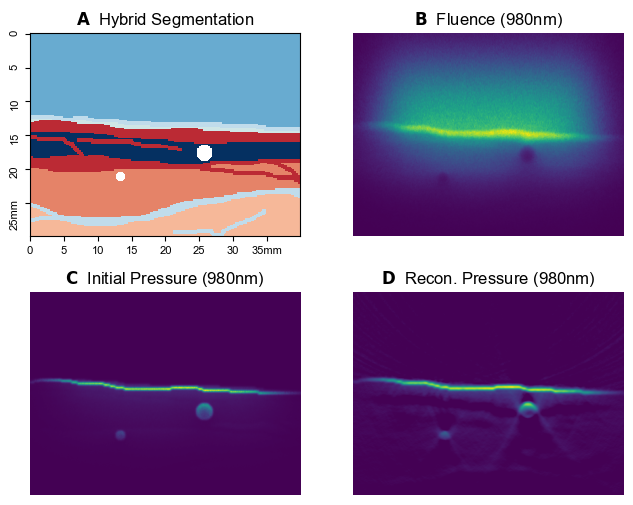

In [21]:
xticks     = [int(x) for x in np.arange(0, seg_mask.shape[1], 50) * 0.1]
xticks[-1] = '35mm'
yticks     = [int(y) for y in np.arange(0, seg_mask.shape[0], 50) * 0.1]
yticks[-1] = '25mm'

fig_width  = 3.4 * 2
fig_height = (fig_width / (400 * 2)) * (300 * 2)

fig, axes = plt.subplots(2, 2, figsize=(fig_width, fig_height))

axes[0, 0].imshow(seg_mask, cmap=cmap, norm=norm, interpolation='nearest')
axes[0, 0].set_title(r"$\mathbf{A}$  Hybrid Segmentation")
axes[0, 0].set_xticks(np.arange(0, seg_mask.shape[1], 50))
axes[0, 0].set_xticklabels(xticks)
axes[0, 0].set_yticks(np.arange(0, seg_mask.shape[0], 50))
axes[0, 0].set_yticklabels(yticks, rotation=90)
axes[0, 0].grid(False)

axes[0, 1].imshow(fluence, cmap='viridis')
axes[0, 1].set_title(r"$\mathbf{B}$  Fluence (980nm)")
axes[0, 1].axis('off')

axes[1, 0].imshow(initial_pressure, cmap='viridis')
axes[1, 0].set_title(r"$\mathbf{C}$  Initial Pressure (980nm)")
axes[1, 0].axis('off')

axes[1, 1].imshow(recon_unmixed_hbo2, cmap='viridis')
axes[1, 1].set_title(r"$\mathbf{D}$  Recon. Pressure (980nm)")
axes[1, 1].axis('off')

plt.tight_layout(pad=1.0)
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/sim_samples.pdf", bbox_inches='tight', dpi=300)
plt.show()
